In [1]:
'''Analyze feature importance in ensemble models to identify the most influential applicant attributes affecting 
admission decisions, supporting transparent and fair selection processes'''

'Analyze feature importance in ensemble models to identify the most influential applicant attributes affecting \nadmission decisions, supporting transparent and fair selection processes'

In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# load dataset
df = pd.read_csv('Adm.csv')
print(df.head())

   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0           1        337          118                  4  4.5  4.5  9.65   
1           2        324          107                  4  4.0  4.5  8.87   
2           3        316          104                  3  3.0  3.5  8.00   
3           4        322          110                  3  3.5  2.5  8.67   
4           5        314          103                  2  2.0  3.0  8.21   

   Research  Chance of Admit Application_DateTime  \
0         1             0.92  2022-01-01 09:00:00   
1         1             0.76  2022-01-02 09:00:00   
2         1             0.72  2022-01-04 09:00:00   
3         1             0.80  2022-01-06 09:00:00   
4         0             0.65  2022-01-08 09:00:00   

                              University_Name region  
0    Indian Institute of Technology Kharagpur   East  
1  National Institute of Technology Karnataka  South  
2                          Gujarat University   West  
3   

In [4]:
# check dataset summary
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB
None
        Serial No.    GRE Score  TOEFL Score  University Rating          SOP  \
count  1000.000000  1000.000000 

In [5]:
# prepare applicant features and target
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Chance of Admit']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# train random forest ensemble model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print('Random Forest R2 Score:', r2_score(y_test, rf_pred))

Random Forest R2 Score: 0.14715532386454533


In [7]:
# calculate random forest feature importances
rf_importance = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)
print('Random Forest Feature Importance:')
print(rf_importance.sort_values(ascending=False))

Random Forest Feature Importance:
CGPA                 0.287658
GRE Score            0.188241
TOEFL Score          0.177847
LOR                  0.123321
SOP                  0.123024
University Rating    0.067137
Research             0.032771
dtype: float64


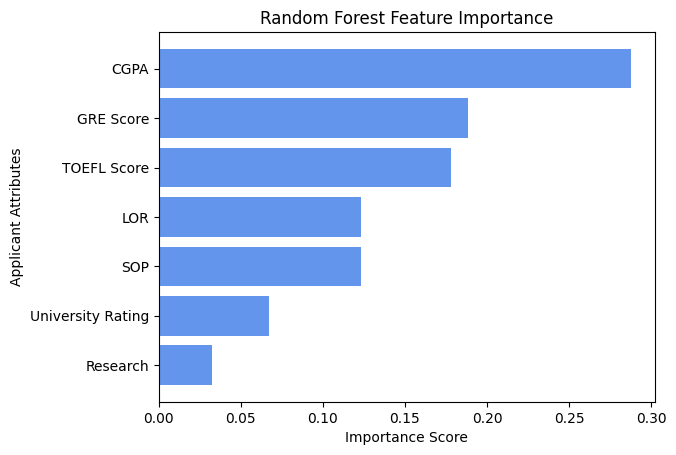

In [8]:
# plot random forest feature importances
plt.barh(rf_importance.index, rf_importance.values, color='cornflowerblue')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Applicant Attributes')
plt.show()

In [9]:
# train gradient boosting ensemble model
gb_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)
print('Gradient Boosting R2 Score:', r2_score(y_test, gb_pred))

Gradient Boosting R2 Score: 0.09673823009819349


In [10]:
# calculate gradient boosting feature importances
gb_importance = pd.Series(gb_model.feature_importances_, index=features).sort_values(ascending=True)
print('Gradient Boosting Feature Importance:')
print(gb_importance.sort_values(ascending=False))

Gradient Boosting Feature Importance:
CGPA                 0.332907
GRE Score            0.170012
TOEFL Score          0.162731
LOR                  0.119199
SOP                  0.114741
Research             0.062552
University Rating    0.037859
dtype: float64


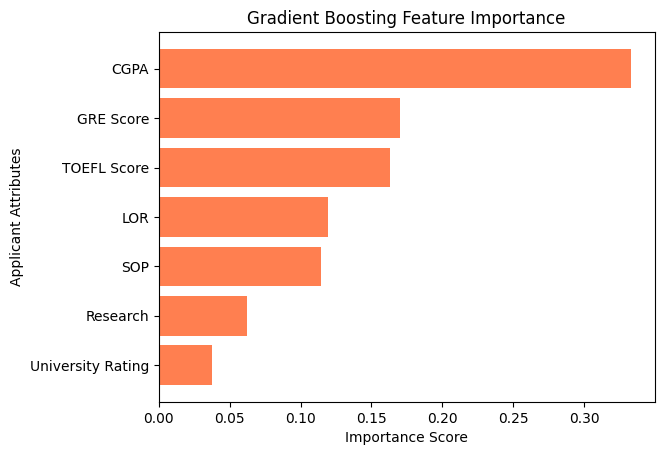

In [11]:
# plot gradient boosting feature importances
plt.barh(gb_importance.index, gb_importance.values, color='coral')
plt.title('Gradient Boosting Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Applicant Attributes')
plt.show()

In [12]:
# compare feature importances across ensemble models
comparison_df = pd.DataFrame({'Random Forest': rf_importance.sort_values(ascending=False), 'Gradient Boosting': gb_importance.sort_values(ascending=False)})
print(comparison_df)

                   Random Forest  Gradient Boosting
CGPA                    0.287658           0.332907
GRE Score               0.188241           0.170012
LOR                     0.123321           0.119199
Research                0.032771           0.062552
SOP                     0.123024           0.114741
TOEFL Score             0.177847           0.162731
University Rating       0.067137           0.037859


In [13]:
# display most influential attributes for fair admission
print('Top Influential Attributes:')
for i, feature in enumerate(rf_importance.sort_values(ascending=False).index[:3], 1):
    print(f'{i}. {feature}: {rf_importance[feature]:.4f}')

Top Influential Attributes:
1. CGPA: 0.2877
2. GRE Score: 0.1882
3. TOEFL Score: 0.1778


In [14]:
# final summary of feature importance
# academic scores like cgpa gre and toefl are the most important factors for admission
# using these objective scores helps keep the selection process fair and transparent